In [314]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df_maternal = pd.read_csv('../data/raw/maternal_health_risk.csv')


In [315]:
print("\n     VERİ SETİNİN YAPISAL ANALİZİ")

print("\n------------------------------------------------------------------------------\n")

print("Veri Seti Boyutu:", df_maternal.shape)

print("\n------------------------------------------------------------------------------\n")

print("İlk 5 Satır:\n\n", df_maternal.head())

print("\n------------------------------------------------------------------------------\n")


print("Veri Seti Bilgileri:\n") 
df_maternal.info()

print("\n------------------------------------------------------------------------------\n")

print("Eksik Değer Sayıları:\n") 
print(df_maternal.isnull().sum())

print("\n------------------------------------------------------------------------------\n")

print("Tekrarlanan Satır Sayısı:", df_maternal.duplicated().sum())

print("\n------------------------------------------------------------------------------\n")

print("Özet İstatistikler:\n")
print(df_maternal.describe().T)

print("\n------------------------------------------------------------------------------\n")

print("Hedef Değişken (RiskLevel) Sınıf Dağılımı:\n")
print(df_maternal['RiskLevel'].value_counts())

print("\n------------------------------------------------------------------------------\n")

print("RiskLevel Sınıf Oranları (%):\n")
print(df_maternal['RiskLevel'].value_counts(normalize=True) * 100)

print("\n------------------------------------------------------------------------------\n")



     VERİ SETİNİN YAPISAL ANALİZİ

------------------------------------------------------------------------------

Veri Seti Boyutu: (1014, 7)

------------------------------------------------------------------------------

İlk 5 Satır:

    Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  RiskLevel
0   25         130           80  15.0      98.0         86  high risk
1   35         140           90  13.0      98.0         70  high risk
2   29          90           70   8.0     100.0         80  high risk
3   30         140           85   7.0      98.0         70  high risk
4   35         120           60   6.1      98.0         76   low risk

------------------------------------------------------------------------------

Veri Seti Bilgileri:

<class 'pandas.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP 


   VERİ SETİNİN GÖRSEL ANALİZİ

-----------------------------------------------------------------------------------------------------------------------------------------------------------

Sınıf Dağılımı (Count Plot)


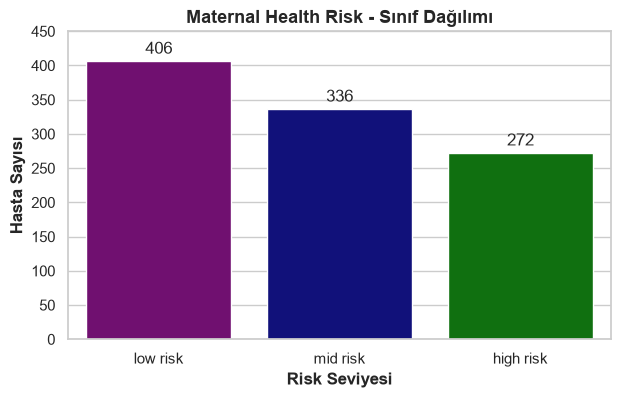


-----------------------------------------------------------------------------------------------------------------------------------------------------------

Sayısal Özelliklerin Dağılımı (Histogram & KDE)


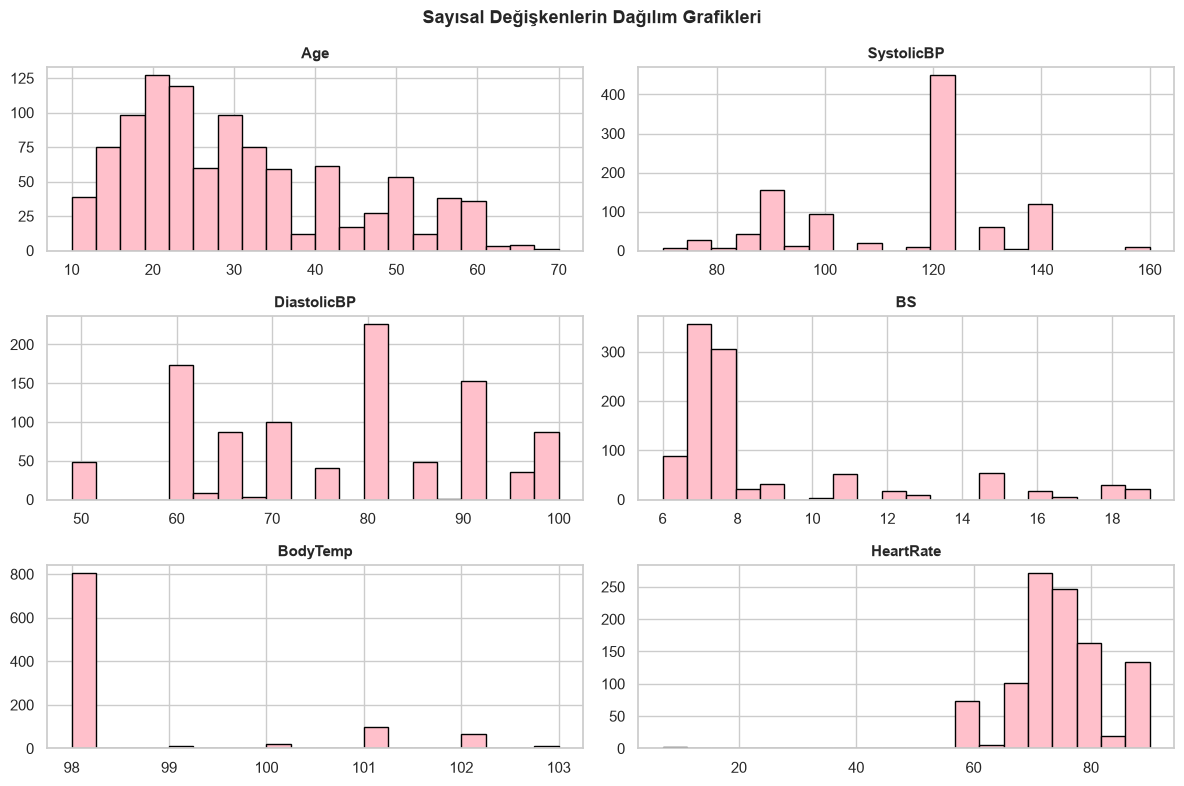


-----------------------------------------------------------------------------------------------------------------------------------------------------------

Aykırı Değer (Outlier) Analizi (Box Plot)


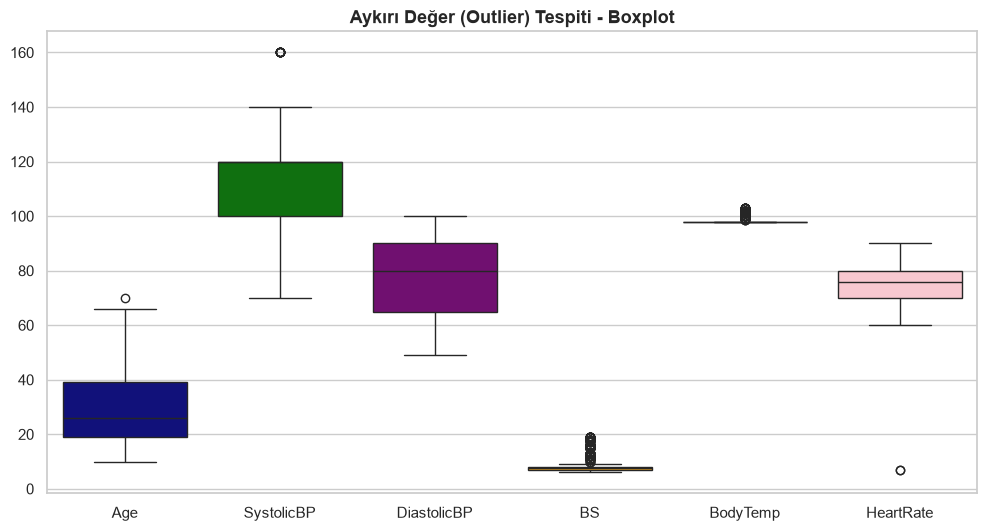


-----------------------------------------------------------------------------------------------------------------------------------------------------------

Korelasyon Matrisi (Heatmap)


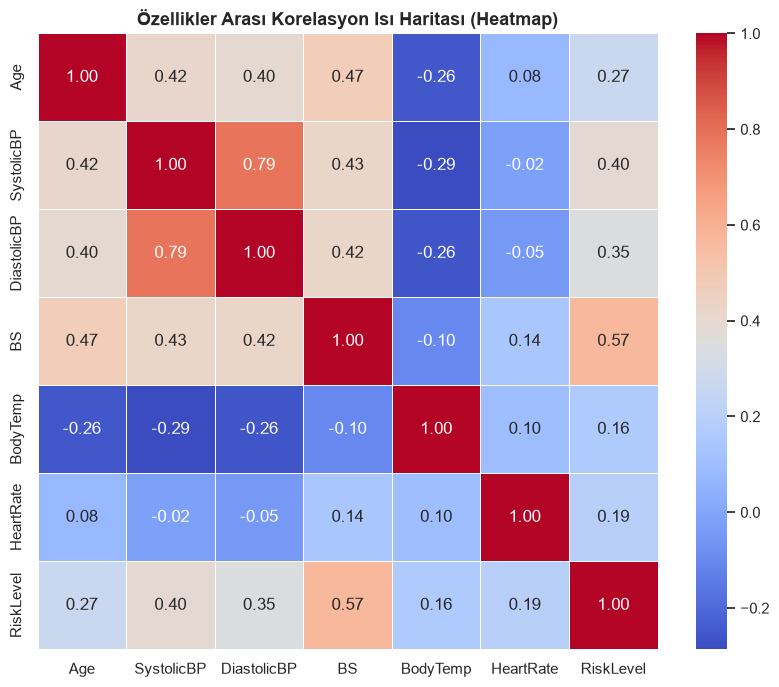


-----------------------------------------------------------------------------------------------------------------------------------------------------------



In [316]:
print("\n   VERİ SETİNİN GÖRSEL ANALİZİ")

import os
os.makedirs("../reports/figures", exist_ok=True)

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

print("Sınıf Dağılımı (Count Plot)")

sira = ["low risk", "mid risk", "high risk"]
renkler = {"low risk": 'purple', "mid risk": 'darkblue', "high risk": 'green'}

plt.figure(figsize=(7, 4))

ax = sns.countplot(data=df_maternal, x="RiskLevel", hue="RiskLevel", order=sira, hue_order=sira, palette=renkler, legend=False)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
    
plt.title("Maternal Health Risk - Sınıf Dağılımı", fontsize=13, fontweight="bold")
plt.xlabel("Risk Seviyesi", fontweight="bold")
plt.ylabel("Hasta Sayısı", fontweight="bold")
plt.ylim(0, 450)
plt.yticks(range(0, 451, 50))
plt.savefig("../reports/figures/maternal_countplot.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

print("Sayısal Özelliklerin Dağılımı (Histogram & KDE)")

num_cols = df_maternal.select_dtypes(include=[np.number]).columns

axes = df_maternal[num_cols].hist(bins=20, figsize=(12, 8), color='pink', edgecolor='black')
plt.suptitle('Sayısal Değişkenlerin Dağılım Grafikleri', fontsize=13, fontweight='bold')
for ax in axes.flatten():
    ax.set_title(ax.get_title(), fontweight='bold', fontsize=11)
plt.tight_layout()
plt.savefig("../reports/figures/maternal_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

print("Aykırı Değer (Outlier) Analizi (Box Plot)")

plt.figure(figsize=(12, 6))
custom_colors = ['darkblue', 'green', 'purple', 'orange', 'yellow', 'pink']
sns.boxplot(data=df_maternal[num_cols], palette=custom_colors)
plt.title('Aykırı Değer (Outlier) Tespiti - Boxplot', fontsize=13, fontweight='bold')
plt.xticks(rotation=0)
plt.savefig("../reports/figures/maternal_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

print("Korelasyon Matrisi (Heatmap)")

plt.figure(figsize=(10, 8))
sns.heatmap(df_corr_prep.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Özellikler Arası Korelasyon Isı Haritası (Heatmap)', fontsize=13, fontweight='bold')
plt.savefig("../reports/figures/maternal_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n-----------------------------------------------------------------------------------------------------------------------------------------------------------\n")

